# Fake Job Postings Detector — end-to-end machine-learning notebook

**Problem.** Fake job ads waste job-seekers' time and can cost them money or personal data. Can we flag suspicious postings automatically from the text and metadata of the ad?

**Data.** EMSCAD (Employment Scam Aegean Dataset), as published on Kaggle in *"Real / Fake Job Posting Prediction"*: 17,880 job postings, 18 columns, target column `fraudulent` (1 = fake).

**Approach.** Traditional machine learning only (no deep learning): TF-IDF text features + structured features, three classical models, compared fairly with cross-validation and evaluated once on a held-out test set.

| # | Step | What happens |
|---|------|--------------|
| 1 | Load | Read the CSV, sanity checks |
| 2 | EDA | Target balance, missing values, duplicates, which columns separate fake from real |
| 3 | Preprocessing | Remove duplicates, clean text, engineer features, define the vectorising/encoding pipeline |
| 4 | Train/test split | Stratified **and** group-aware split (no shared descriptions between train and test) |
| 5 | Feature selection | Drop/keep decisions backed by evidence (train set only) |
| 6 | Modelling | Baseline + Logistic Regression, Linear SVM, Random Forest; hyper-parameter search with CV |
| 7 | Threshold tuning | Choose the decision threshold from out-of-fold predictions (train set only) |
| 8 | Final evaluation | One evaluation on the untouched test set, with confidence intervals |
| 9 | Interpretation | Which words/features drive the predictions, error analysis, robustness check |
| 10 | Save & wrap-up | Save the model for the Streamlit app, conclusions and limitations |

**Requirements:** Python 3.9+, `pandas`, `numpy`, `scikit-learn >= 1.2`, `matplotlib`, `seaborn`, `joblib`. Put `fake_job_postings.csv` next to this notebook (or change `DATA_PATH`). Full run takes roughly 10–15 minutes on a single CPU core; the random seed is fixed so results are reproducible.

> **Leakage rule used throughout:** anything that *learns* from data (TF-IDF vocabulary, encoders, scalers, hyper-parameters, decision threshold) is fitted on the training set only. The test set is used exactly once, in Section 8.

In [1]:
import os, re, html, time, tempfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore")
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)

SEED = 42
DATA_PATH = "fake_job_postings.csv"      # on Colab: upload the file, or mount Drive and change this path
COLORS = {0: "#4C72B0", 1: "#C44E52"}    # real = blue, fake = red
os.makedirs("figures", exist_ok=True)

def save_fig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


## 1. Load the data

| Column | Meaning |
|---|---|
| `job_id` | Row identifier (no predictive meaning) |
| `title`, `location`, `department` | Basic ad info (`location` looks like `US, NY, New York`) |
| `salary_range` | Free-text salary range (mostly missing) |
| `company_profile`, `description`, `requirements`, `benefits` | The ad text, split into four fields |
| `telecommuting`, `has_company_logo`, `has_questions` | Binary flags |
| `employment_type`, `required_experience`, `required_education`, `industry`, `function` | Categorical fields |
| `fraudulent` | **Target**: 1 = fake posting, 0 = real |

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head(3).T)

assert set(df_raw["fraudulent"].unique()) == {0, 1}, "target must be binary"
assert df_raw["job_id"].is_unique, "job_id must be unique"
print("Sanity checks passed: binary target, unique job_id")

Shape: (17880, 18)


,0,1,2
job_id,1,2,3
title,Marketing Intern,Customer Service - Cloud Video Production,Commissioning Machinery Assistant (CMA)
location,"US, NY, New York","NZ, , Auckland","US, IA, Wever"
department,Marketing,Success,NaN
salary_range,NaN,NaN,NaN
company_profile,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and ...","90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Production Serv...","Valor Services provides Workforce Solutions that meet the needs of companies across the Private Sector, wi..."
description,"Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated reci...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing skills? M...,"Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assistant that ..."
requirements,Experience with content management systems a major plus (any blogging counts!)Familiar with the Food52 edi...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Seconds team an...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activities with ...
benefits,NaN,What you will get from usThrough being part of the 90 Seconds team you will gain:experience working on pro...,NaN
telecommuting,0,0,0


Sanity checks passed: binary target, unique job_id


## 2. Exploratory data analysis (EDA)

EDA here is **descriptive**: it helps us understand the data and decide what to engineer. Nothing is fitted to a model in this section; every learned step comes after the train/test split.

### 2.1 Target distribution

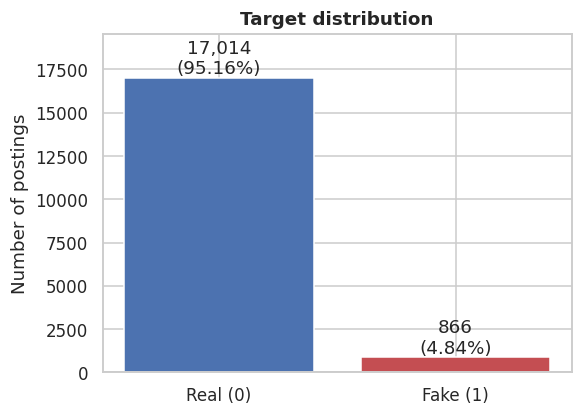

A 'model' that always answers 'real' would be 95.16% accurate and catch 0 fake postings.
=> accuracy is a misleading metric here; we will focus on precision, recall, F1 and PR-AUC for the fake class.


In [3]:
counts = df_raw["fraudulent"].value_counts().sort_index()
share = df_raw["fraudulent"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(["Real (0)", "Fake (1)"], counts.values, color=[COLORS[0], COLORS[1]])
for b, c, s in zip(bars, counts.values, share.values):
    ax.text(b.get_x() + b.get_width() / 2, c, f"{c:,}\n({s:.2f}%)", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Number of postings")
ax.set_title("Target distribution")
save_fig("01_target_distribution")
plt.show()

print(f"A 'model' that always answers 'real' would be {share[0]:.2f}% accurate and catch 0 fake postings.")
print("=> accuracy is a misleading metric here; we will focus on precision, recall, F1 and PR-AUC for the fake class.")

### 2.2 Missing values

Columns with a few missing values only: {'description': 1}


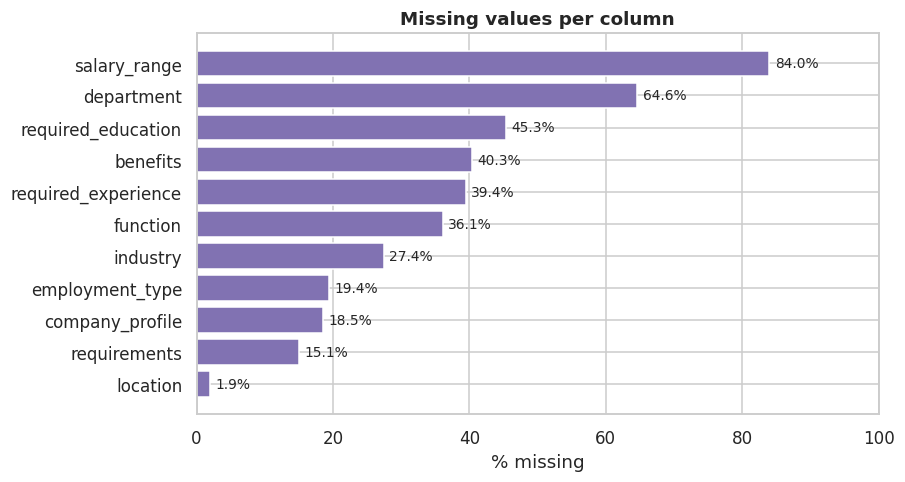

,% missing,fake rate if missing (%),fake rate if present (%),ratio missing/present
column,,,,
company_profile,18.5,17.74,1.91,9.29
employment_type,19.4,6.94,4.34,1.60
required_experience,39.4,6.17,3.98,1.55
required_education,45.3,5.56,4.25,1.31
industry,27.4,5.61,4.55,1.23
requirements,15.1,5.71,4.69,1.22
location,1.9,5.49,4.83,1.14
function,36.1,5.22,4.63,1.13
benefits,40.3,5.05,4.71,1.07


In [4]:
missing_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)
print("Columns with a few missing values only:", {c: int(df_raw[c].isna().sum()) for c in missing_pct[(missing_pct > 0) & (missing_pct < 1)].index})
missing_pct = missing_pct[missing_pct >= 1]          # tiny counts would give meaningless rates

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(missing_pct.index[::-1], missing_pct.values[::-1], color="#8172B2")
for i, v in enumerate(missing_pct.values[::-1]):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("% missing")
ax.set_title("Missing values per column")
save_fig("02_missing_values")
plt.show()

# Is "missing" itself informative? Compare the fake rate when a field is missing vs present.
rows = []
for c in missing_pct.index:
    m = df_raw[c].isna()
    rows.append({"column": c,
                 "% missing": round(m.mean() * 100, 1),
                 "fake rate if missing (%)": round(df_raw.loc[m, "fraudulent"].mean() * 100, 2),
                 "fake rate if present (%)": round(df_raw.loc[~m, "fraudulent"].mean() * 100, 2)})
missing_info = pd.DataFrame(rows).set_index("column")
missing_info["ratio missing/present"] = (missing_info["fake rate if missing (%)"] / missing_info["fake rate if present (%)"]).round(2)
display(missing_info.sort_values("ratio missing/present", ascending=False))

### 2.3 Data quality: duplicates

In [5]:
content_cols = [c for c in df_raw.columns if c != "job_id"]          # everything except the identifier
dup_mask = df_raw.duplicated(subset=content_cols, keep="first")
print(f"Exact duplicate postings (ignoring job_id): {dup_mask.sum()}")

dup_groups = (df_raw[df_raw.duplicated(subset=content_cols, keep=False)]
              .groupby(content_cols, dropna=False)["fraudulent"].nunique())
print(f"Duplicate groups: {len(dup_groups)} | groups with conflicting labels: {(dup_groups > 1).sum()}")

tmp = df_raw[~dup_mask]
desc_counts = tmp["description"].value_counts()
shared_desc = tmp["description"].map(desc_counts) > 1
print(f"After removing exact duplicates, {shared_desc.sum():,} postings ({shared_desc.mean()*100:.1f}%) still share an identical "
      f"description with at least one other posting (same ad re-posted with a different title/location).")
print("=> exact duplicates will be removed, and the train/test split must keep re-posted / near-identical ads on the same side.")

Exact duplicate postings (ignoring job_id): 281
Duplicate groups: 246 | groups with conflicting labels: 0
After removing exact duplicates, 3,846 postings (21.9%) still share an identical description with at least one other posting (same ad re-posted with a different title/location).
=> exact duplicates will be removed, and the train/test split must keep re-posted / near-identical ads on the same side.


### 2.4 Binary features and simple flags vs. the target

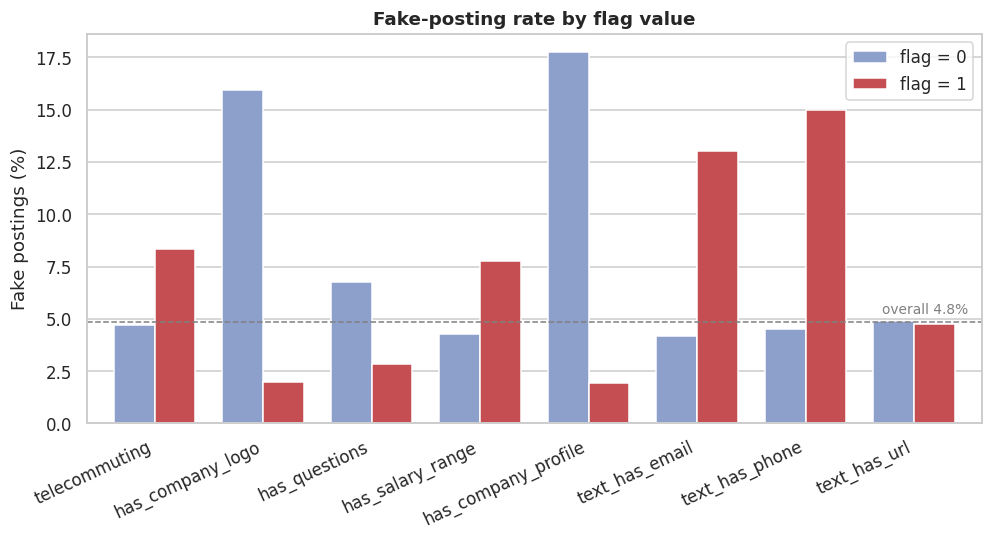

,flag = 0,flag = 1,n (flag = 1)
telecommuting,4.69,8.34,767
has_company_logo,15.93,1.99,14220
has_questions,6.78,2.84,8792
has_salary_range,4.28,7.78,2868
has_company_profile,17.74,1.91,14572
text_has_email,4.18,13.03,1335
text_has_phone,4.54,14.99,527
text_has_url,4.89,4.75,5621


In [6]:
overall_rate = df_raw["fraudulent"].mean() * 100
raw_text = df_raw[["title", "company_profile", "description", "requirements", "benefits"]].fillna("").agg(" ".join, axis=1)

eda_flags = pd.DataFrame({
    "telecommuting": df_raw["telecommuting"],
    "has_company_logo": df_raw["has_company_logo"],
    "has_questions": df_raw["has_questions"],
    "has_salary_range": df_raw["salary_range"].notna().astype(int),
    "has_company_profile": df_raw["company_profile"].notna().astype(int),
    "text_has_email": raw_text.str.contains("#EMAIL_", regex=False).astype(int),
    "text_has_phone": raw_text.str.contains("#PHONE_", regex=False).astype(int),
    "text_has_url": raw_text.str.contains("#URL_", regex=False).astype(int),
})
rate_df = pd.DataFrame({f: df_raw["fraudulent"].groupby(eda_flags[f]).mean() * 100 for f in eda_flags.columns}).T
rate_df.columns = ["flag = 0", "flag = 1"]
rate_df["n (flag = 1)"] = eda_flags.sum().astype(int)

ax = rate_df[["flag = 0", "flag = 1"]].plot.bar(figsize=(10.5, 4.6), color=["#8da0cb", COLORS[1]], width=0.75)
ax.axhline(overall_rate, ls="--", color="gray", lw=1)
ax.text(len(rate_df) - 0.5, overall_rate + 0.4, f"overall {overall_rate:.1f}%", ha="right", color="gray", fontsize=9)
ax.set_ylabel("Fake postings (%)")
ax.set_title("Fake-posting rate by flag value")
plt.xticks(rotation=25, ha="right")
ax.grid(axis="x", visible=False)
save_fig("03_binary_flags")
plt.show()
display(rate_df.round(2))

### 2.5 Categorical fields

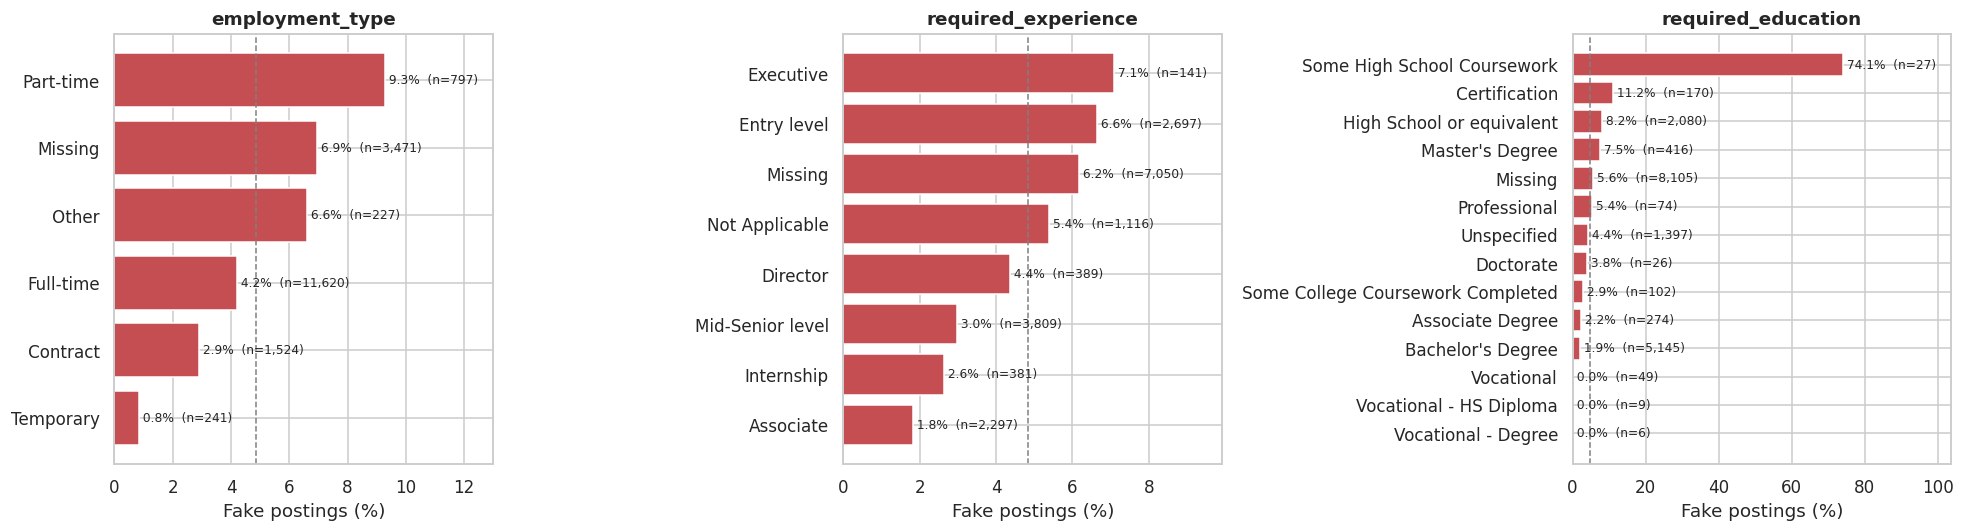

industry:  131 distinct values | function: 37 distinct values


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["employment_type", "required_experience", "required_education"]):
    t = (df_raw.assign(cat=df_raw[col].fillna("Missing")).groupby("cat")["fraudulent"]
         .agg(rate="mean", n="size"))
    t["rate"] *= 100
    t = t.sort_values("rate")
    ax.barh(t.index, t["rate"], color=COLORS[1])
    for i, (r, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(r, i, f" {r:.1f}%  (n={n:,})", va="center", fontsize=8)
    ax.axvline(overall_rate, ls="--", color="gray", lw=1)
    ax.set_xlim(0, t["rate"].max() * 1.4)
    ax.set_title(col)
    ax.set_xlabel("Fake postings (%)")
plt.tight_layout()
save_fig("04_categorical_fields")
plt.show()

print("industry: ", df_raw["industry"].nunique(), "distinct values | function:", df_raw["function"].nunique(), "distinct values")

### 2.6 Country (from `location`)

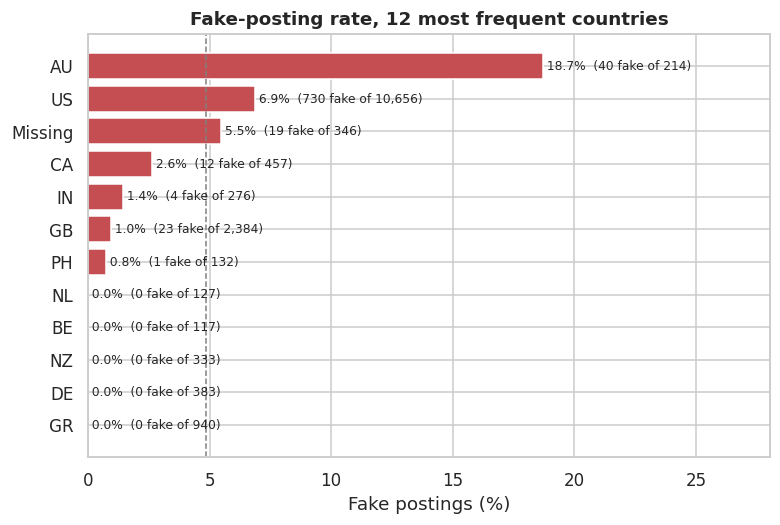

91 distinct country codes in total; the top 12 hold 92% of the postings.


In [8]:
country_raw = df_raw["location"].fillna("Missing").str.split(",").str[0].str.strip().replace("", "Missing")
ct = (df_raw.assign(country=country_raw).groupby("country")["fraudulent"]
      .agg(rate="mean", n="size", fake="sum"))
ct["rate"] *= 100
top = ct.sort_values("n", ascending=False).head(12).sort_values("rate")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["rate"], color=COLORS[1])
for i, (r, n, f) in enumerate(zip(top["rate"], top["n"], top["fake"])):
    ax.text(r, i, f" {r:.1f}%  ({f} fake of {n:,})", va="center", fontsize=8)
ax.axvline(overall_rate, ls="--", color="gray", lw=1)
ax.set_xlim(0, top["rate"].max() * 1.5)
ax.set_xlabel("Fake postings (%)")
ax.set_title("Fake-posting rate, 12 most frequent countries")
save_fig("05_country")
plt.show()
print(f"{ct.shape[0]} distinct country codes in total; the top 12 hold {ct.sort_values('n', ascending=False).head(12)['n'].sum() / len(df_raw) * 100:.0f}% of the postings.")

### 2.7 Text length

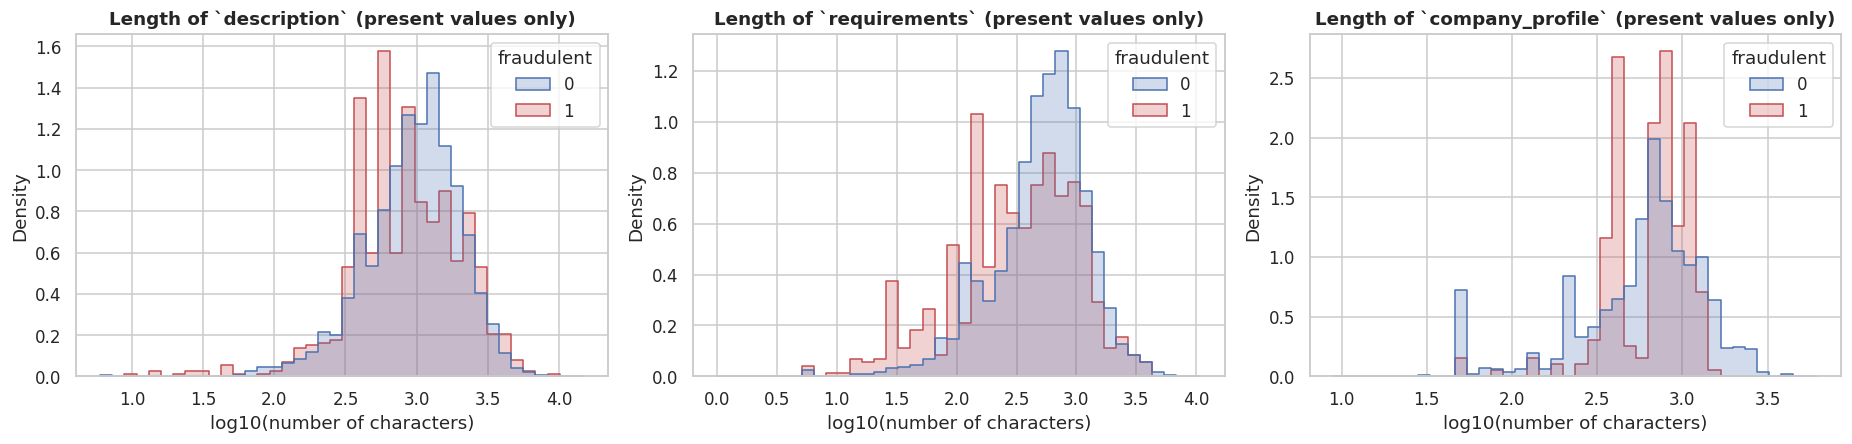

Median length in characters (present values only):


,description,requirements,company_profile
real,1027.0,569.0,684.0
fake,846.0,349.5,718.0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col in zip(axes, ["description", "requirements", "company_profile"]):
    d = df_raw[[col, "fraudulent"]].dropna()
    d = d.assign(log10_chars=np.log10(d[col].str.len().clip(lower=1)))
    sns.histplot(data=d, x="log10_chars", hue="fraudulent", stat="density", common_norm=False,
                 element="step", palette=COLORS, ax=ax, bins=40)
    ax.set_title(f"Length of `{col}` (present values only)")
    ax.set_xlabel("log10(number of characters)")
plt.tight_layout()
save_fig("06_text_length")
plt.show()

med = pd.DataFrame({c: df_raw.dropna(subset=[c]).groupby("fraudulent")[c].apply(lambda s: s.str.len().median())
                    for c in ["description", "requirements", "company_profile"]})
med.index = ["real", "fake"]
print("Median length in characters (present values only):")
display(med)

### 2.8 EDA takeaways

* **Heavy class imbalance**: only about 5% of the ads are fake, so accuracy is useless as a headline metric.
* **Metadata carries real signal**: fake ads are much less likely to have a company logo or screening questions, and the fake rate is far higher when the company profile is missing (see 2.2 and 2.4).
* **Contact details in the text** (masked as `#EMAIL_…#` / `#PHONE_…#` in this dataset) go together with a higher fake rate; masked URLs do not (compare 2.4 with Section 3).
* **Country** shows large differences, but some countries have very few postings, so those percentages are noisy (see the `n` labels in 2.6). We treat rare countries as one "infrequent" group.
* **Duplicates and re-posted ads**: a few hundred exact duplicates and thousands of ads sharing an identical description → they would leak between train and test if we split naively (Section 4 goes further and also catches *near*-identical ads).

## 3. Preprocessing

Two kinds of steps:

1. **Deterministic, row-by-row steps** (no learning): remove duplicates, clean text, create features. Safe to run before the split.
2. **Learned steps** (TF-IDF vocabulary, one-hot categories, scaling): defined here as a `ColumnTransformer`, but *fitted later on the training set only*.

### 3.1 Remove exact duplicates

In [10]:
df = df_raw.drop_duplicates(subset=content_cols, keep="first").reset_index(drop=True)
print(f"Rows before: {len(df_raw):,} | after: {len(df):,} | removed: {len(df_raw) - len(df)}")
print(f"Fake share before: {df_raw['fraudulent'].mean()*100:.2f}% | after: {df['fraudulent'].mean()*100:.2f}%  ({df['fraudulent'].sum()} fake ads)")

Rows before: 17,880 | after: 17,599 | removed: 281
Fake share before: 4.84% | after: 4.86%  (856 fake ads)


### 3.2 Feature-engineering module

The cleaning and feature code is written to a small file, `job_features.py`, so the future Streamlit app can import **exactly the same code** used for training.

What it does:

* **Text cleaning**: decode HTML entities (`&amp;`), replace the masked `#URL_…#`, `#EMAIL_…#`, `#PHONE_…#` tokens with the words `urltoken`, `emailtoken`, `phonetoken` (otherwise every masked value would become a unique, useless word), split words glued together by removed HTML (`ManagerLOCATION` → `Manager LOCATION`), lower-case, drop punctuation.
* **Text fields**: `title` on its own; `company_profile + description + requirements + benefits` merged into one `body` field.
* **Country**: first part of `location`.
* **Missing values**: categorical → the category `"Missing"`; text → empty string; plus explicit indicator flags (`has_company_profile`, `has_requirements`, `has_benefits`, `has_salary`), because missingness itself is informative (2.2).
* **Extra features**: masked email / phone / URL present, number of `!`, share of capital letters in the description, and text lengths (log-scaled to tame outliers).
* **Dropped columns**: `job_id` (identifier), `department` (65% missing, free text with thousands of values), raw `salary_range` (free text; reduced to a flag).

In [11]:
%%writefile job_features.py
"""Feature engineering for the Fake Job Postings project (shared by the notebook and the Streamlit app)."""
import re
import html
import numpy as np
import pandas as pd

TEXT_COLS = ["title", "company_profile", "description", "requirements", "benefits"]
BODY_COLS = ["company_profile", "description", "requirements", "benefits"]
CAT_COLS = ["country", "employment_type", "required_experience", "required_education", "industry", "function"]
NUM_COLS = ["telecommuting", "has_company_logo", "has_questions",
            "has_salary", "has_company_profile", "has_requirements", "has_benefits",
            "has_email", "has_phone", "has_url",
            "log_n_exclaim", "caps_ratio",
            "log_len_description", "log_len_requirements", "log_len_company_profile", "log_len_benefits"]

URL_RE = re.compile(r"#URL_[0-9a-fA-F]+#")
EMAIL_RE = re.compile(r"#EMAIL_[0-9a-fA-F]+#")
PHONE_RE = re.compile(r"#PHONE_[0-9a-fA-F]+#")


def clean_text(s):
    """Lower-case, de-HTML and de-mask a text field; returns '' for missing values."""
    if not isinstance(s, str):
        return ""
    s = html.unescape(s)
    s = URL_RE.sub(" urltoken ", s)
    s = EMAIL_RE.sub(" emailtoken ", s)
    s = PHONE_RE.sub(" phonetoken ", s)
    s = re.sub(r"([a-z])([A-Z])", r"\1 \2", s)          # "ManagerLOCATION" -> "Manager LOCATION"
    s = re.sub(r"[^A-Za-z0-9 ]+", " ", s).lower()
    return re.sub(r"\s+", " ", s).strip()


def _caps_ratio(text):
    letters = sum(ch.isalpha() for ch in text)
    return sum(ch.isupper() for ch in text) / letters if letters else 0.0


def build_features(df):
    """Turn raw posting columns into the engineered feature table used by the models."""
    out = pd.DataFrame(index=df.index)
    raw_all = df[TEXT_COLS].fillna("").agg(" ".join, axis=1)

    out["title_clean"] = df["title"].map(clean_text)
    out["body_clean"] = df[BODY_COLS].fillna("").agg(" ".join, axis=1).map(clean_text)

    out["country"] = df["location"].fillna("Missing").str.split(",").str[0].str.strip().replace("", "Missing")
    for c in ["employment_type", "required_experience", "required_education", "industry", "function"]:
        out[c] = df[c].fillna("Missing")

    for c in ["telecommuting", "has_company_logo", "has_questions"]:
        out[c] = df[c].astype(int)
    out["has_salary"] = df["salary_range"].notna().astype(int)
    out["has_company_profile"] = df["company_profile"].notna().astype(int)
    out["has_requirements"] = df["requirements"].notna().astype(int)
    out["has_benefits"] = df["benefits"].notna().astype(int)

    out["has_email"] = raw_all.str.contains(EMAIL_RE).astype(int)
    out["has_phone"] = raw_all.str.contains(PHONE_RE).astype(int)
    out["has_url"] = raw_all.str.contains(URL_RE).astype(int)
    out["log_n_exclaim"] = np.log1p(raw_all.str.count("!"))
    out["caps_ratio"] = df["description"].fillna("").map(_caps_ratio)
    for c in ["description", "requirements", "company_profile", "benefits"]:
        out[f"log_len_{c}"] = np.log1p(df[c].fillna("").str.len())
    return out

Writing job_features.py


In [12]:
from job_features import clean_text, build_features, CAT_COLS, NUM_COLS

# Show what the cleaning does on a real example (an ad that contains a masked e-mail address)
row = df.loc[df["description"].str.contains("#EMAIL_", regex=False, na=False)].iloc[0]
i = row["description"].find("#EMAIL_")
snippet = row["description"][max(0, i - 160): i + 110]
print("RAW    :", snippet)
print("CLEANED:", clean_text(snippet))

RAW    : mers.• Experience developing in another scripting/front-end language.• Excellent communication skillsIf you are interested, please send your updated profile to #EMAIL_897dfb1f33f6c34f2bed521623e9808aa4e62d89a6c0284cfe89393e4457e628#Hiring for Sales Account Director(adve
CLEANED: mers experience developing in another scripting front end language excellent communication skills if you are interested please send your updated profile to emailtoken hiring for sales account director adve


### 3.3 Build the feature table

In [13]:
t0 = time.time()
X = build_features(df)
y = df["fraudulent"].to_numpy()
print(f"Feature table: {X.shape[0]:,} rows x {X.shape[1]} columns ({time.time() - t0:.1f}s)")

assert X.isna().sum().sum() == 0, "no missing values should remain after preprocessing"
assert len(X) == len(y)
print("No missing values remain.\n")

display(X[CAT_COLS].nunique().rename("distinct values").to_frame().T)
display(X[NUM_COLS].describe().T[["mean", "std", "min", "max"]].round(3))

Feature table: 17,599 rows x 24 columns (6.3s)
No missing values remain.



,country,employment_type,required_experience,required_education,industry,function
distinct values,91,6,8,14,132,38


,mean,std,min,max
telecommuting,0.043,0.203,0.0,1.000
has_company_logo,0.794,0.404,0.0,1.000
has_questions,0.492,0.500,0.0,1.000
has_salary,0.161,0.367,0.0,1.000
has_company_profile,0.814,0.390,0.0,1.000
has_requirements,0.849,0.358,0.0,1.000
has_benefits,0.596,0.491,0.0,1.000
has_email,0.075,0.263,0.0,1.000
has_phone,0.029,0.169,0.0,1.000
has_url,0.315,0.465,0.0,1.000


### 3.4 Text exploration after cleaning (descriptive)

Which words are typical of fake or real ads? For every word we compute the smoothed log-odds ratio of appearing in a fake vs. a real ad. To stop a single re-posted ad from dominating, we count **one ad per identical description**, and we only look at reasonably frequent words (at least 20 fake ads for the fake side, at least 100 real ads for the real side).

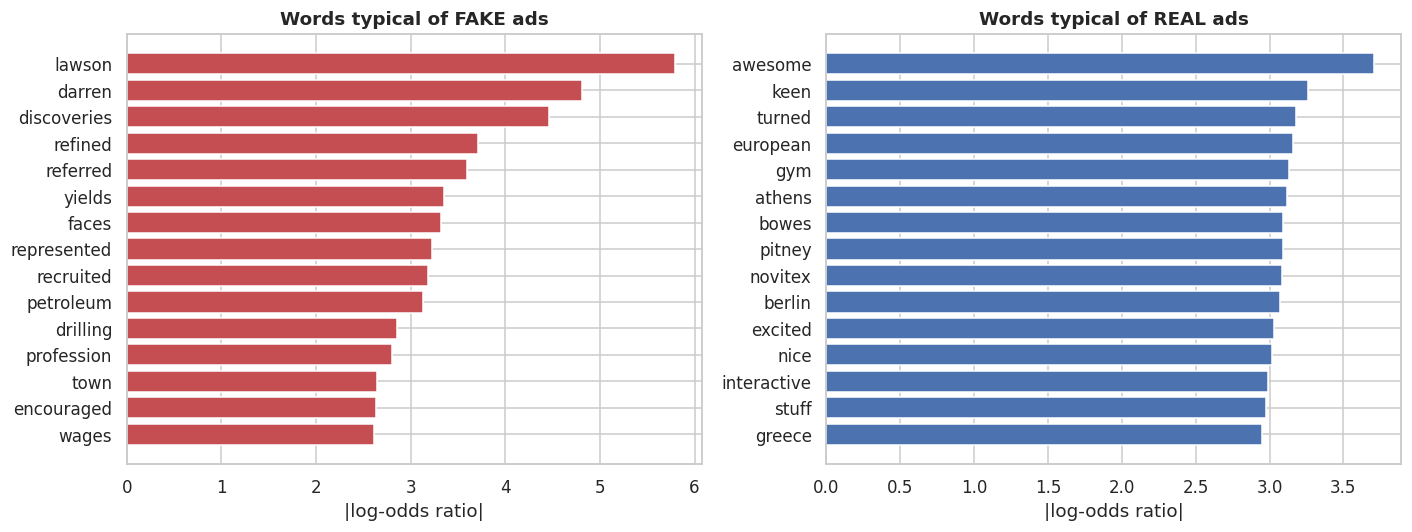

word,lawson,darren,discoveries,refined,referred,yields,faces,represented
fake_docs,40,40,39,32,43,26,32,43
real_docs,2,7,10,18,28,21,27,41


In [14]:
from sklearn.feature_extraction.text import CountVectorizer

first_of_desc = ~df["description"].duplicated().to_numpy()          # one ad per identical description
Xw, yw = X.loc[first_of_desc], y[first_of_desc]
cv_words = CountVectorizer(stop_words="english", min_df=40, binary=True, token_pattern=r"(?u)\b[a-z]{3,}\b")
B = cv_words.fit_transform(Xw["body_clean"])
words = np.array(cv_words.get_feature_names_out())

fake_docs = np.asarray(B[yw == 1].sum(axis=0)).ravel()
real_docs = np.asarray(B[yw == 0].sum(axis=0)).ravel()
p_fake = (fake_docs + 1) / ((yw == 1).sum() + 2)
p_real = (real_docs + 1) / ((yw == 0).sum() + 2)
log_odds = np.log((p_fake / (1 - p_fake)) / (p_real / (1 - p_real)))

words_df = pd.DataFrame({"word": words, "log_odds": log_odds, "fake_docs": fake_docs, "real_docs": real_docs})
top_fake = words_df[words_df["fake_docs"] >= 20].nlargest(15, "log_odds").iloc[::-1]
top_real = words_df[words_df["real_docs"] >= 100].nsmallest(15, "log_odds").iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top_fake["word"], top_fake["log_odds"], color=COLORS[1]); axes[0].set_title("Words typical of FAKE ads")
axes[1].barh(top_real["word"], -top_real["log_odds"], color=COLORS[0]); axes[1].set_title("Words typical of REAL ads")
for ax in axes: ax.set_xlabel("|log-odds ratio|")
plt.tight_layout()
save_fig("07_top_words")
plt.show()
display(top_fake.iloc[::-1][["word", "fake_docs", "real_docs"]].head(8).set_index("word").T)

**Reading the chart carefully.** The most distinctive words are often *names, places and industry terms* (for example oil-and-gas vocabulary on the fake side, or Greek/European place names on the real side), not universal "scam phrases". They come from a handful of recurring scam campaigns and employers in this dataset. That is a warning sign for **memorisation**: a model can look excellent by recognising a known template. This is why Section 4 keeps near-identical ads on one side of the split, and why Section 9.3 tests the model on completely unseen campaigns and companies.

### 3.5 The learned part of preprocessing (defined now, fitted later)

* **Text** → TF-IDF (`title`: unigrams+bigrams; `body`: unigrams+bigrams, English stop-words removed, sub-linear term frequency).
* **Categoricals** → one-hot encoding; categories with fewer than 30 postings are pooled into an "infrequent" group.
* **Numeric/binary** → standardised (needed by the linear models; harmless for trees).

Everything sits in one scikit-learn `Pipeline`, so during cross-validation each fold re-learns its vocabulary/scaling from its own training part only.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(cat_cols=CAT_COLS, num_cols=NUM_COLS, body_max_features=30000, body_ngrams=(1, 2),
                      scale_num=True, k_best=None):
    """ColumnTransformer: TF-IDF (title, body) + one-hot (categoricals) + scaler (numeric).
    k_best: optionally keep only the k body terms with the highest chi-squared score."""
    body_vec = TfidfVectorizer(ngram_range=body_ngrams, min_df=5, max_df=0.9, max_features=body_max_features,
                               sublinear_tf=True, stop_words="english")
    body = body_vec if k_best is None else Pipeline([("tfidf", body_vec), ("select", SelectKBest(chi2, k=k_best))])
    parts = [("title", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words="english"), "title_clean"),
             ("body", body, "body_clean")]
    if len(cat_cols):
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30), list(cat_cols)))
    if len(num_cols):
        parts.append(("num", StandardScaler() if scale_num else "passthrough", list(num_cols)))
    return ColumnTransformer(parts)

print("Preprocessing pipeline defined (not fitted yet).")

Preprocessing pipeline defined (not fitted yet).


## 4. Train / test split

**Why not a plain random split?** Many ads in this dataset are the *same ad posted again* (identical description, sometimes with a different title or city), and many fake ads come from recurring scam **templates** (Section 3.4). With a random split, near-copies of a training ad land in the test set and the model is rewarded for *remembering* rather than *generalising*.

**What we do:** a **stratified, group-aware split** where a *group* is a set of near-identical ads:

1. **Near-duplicate detection.** TF-IDF vectors of each ad's text; two ads are linked if their cosine similarity is at least 0.9. Ads with an identical description are linked too. Connected ads form one group. (This uses no labels and is only a tool for partitioning the data, not a model feature.)
2. `StratifiedGroupKFold`: all ads of a group go to the same side, and train/test keep the same ~5% fake share.

One of the 5 folds (~20%) becomes the **test set**; we do not touch it until Section 8. The same splitter is reused for cross-validation *inside* the training set.

In [16]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors

def near_duplicate_edges(text, min_similarity=0.9):
    """Pairs of ads whose TF-IDF cosine similarity is >= min_similarity."""
    M = TfidfVectorizer(min_df=2, max_df=0.5, max_features=50000, sublinear_tf=True, stop_words="english").fit_transform(text)
    nn = NearestNeighbors(metric="cosine", algorithm="brute").fit(M)
    neigh = nn.radius_neighbors(M, radius=1 - min_similarity, return_distance=False)
    return np.repeat(np.arange(len(neigh)), [len(a) for a in neigh]), np.concatenate(neigh)

def same_key_edges(keys):
    """Link every row to the first row with the same key (rows with a missing key are not linked)."""
    codes, _ = pd.factorize(pd.Series(keys))
    order = np.arange(len(codes))
    first = pd.Series(order).groupby(codes).transform("min").to_numpy()
    keep = codes >= 0
    return order[keep], first[keep]

def groups_from_edges(n, *edge_sets):
    r = np.concatenate([e[0] for e in edge_sets]); c = np.concatenate([e[1] for e in edge_sets])
    return connected_components(coo_matrix((np.ones(len(r)), (r, c)), shape=(n, n)), directed=False)[1]

t0 = time.time()
edges_near = near_duplicate_edges(X["body_clean"])
edges_desc = same_key_edges(df["description"])
dup_group = groups_from_edges(len(df), edges_near, edges_desc)
sizes = np.bincount(dup_group)
in_multi = sizes[dup_group] > 1
print(f"Near-duplicate grouping ({time.time() - t0:.0f}s): {len(sizes):,} groups for {len(df):,} ads; largest group = {sizes.max()} ads")
print(f"Ads that belong to a group of 2+ near-identical ads: {in_multi.mean()*100:.1f}% overall, "
      f"{in_multi[y == 1].mean()*100:.1f}% of the fake ads ({int(in_multi[y == 1].sum())} of {int(y.sum())})")

Near-duplicate grouping (13s): 12,030 groups for 17,599 ads; largest group = 414 ads
Ads that belong to a group of 2+ near-identical ads: 42.3% overall, 51.9% of the fake ads (444 of 856)


In [17]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=dup_group))

X_train, X_test = X.iloc[train_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)
y_train, y_test = y[train_idx], y[test_idx]
g_train = dup_group[train_idx]
df_train, df_test = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)

summary = pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "fake ads": [int(y_train.sum()), int(y_test.sum())],
    "fake share (%)": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["train", "test"])
display(summary)

assert len(set(dup_group[train_idx]) & set(dup_group[test_idx])) == 0
print("Near-duplicate groups shared between train and test: 0")
assert len(set(df_train["description"].dropna()) & set(df_test["description"].dropna())) == 0
print("Identical descriptions shared between train and test: 0")

# Residual overlap that we deliberately do NOT remove: the same company posting different jobs
cp_train = set(df_train["company_profile"].dropna())
seen = df_test["company_profile"].map(lambda c: isinstance(c, str) and c in cp_train)
print(f"Test ads whose company profile also appears in train: {seen.mean()*100:.0f}% overall, "
      f"{seen[y_test == 1].mean()*100:.0f}% among fake ads (examined again in the stress test of Section 9.3).")

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)   # same idea for CV inside the training set

,rows,fake ads,fake share (%)
train,14079,685,4.87
test,3520,171,4.86


Near-duplicate groups shared between train and test: 0
Identical descriptions shared between train and test: 0
Test ads whose company profile also appears in train: 77% overall, 23% among fake ads (examined again in the stress test of Section 9.3).


### 4.1 Does the grouping matter? (train set only)
Same model, same data; only the way we cut the training set into folds changes. If cross-validation reports *higher* scores with looser grouping, the extra score is leakage, not skill.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

lr_check = Pipeline([("prep", make_preprocessor()),
                     ("clf", LogisticRegression(C=10, class_weight="balanced", max_iter=3000))])
desc_group_train = pd.factorize(df_train["description"])[0]
t0 = time.time()
schemes = {
    "1. random stratified folds":                dict(cv=StratifiedKFold(5, shuffle=True, random_state=SEED), groups=None),
    "2. grouped by identical description":       dict(cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), groups=desc_group_train),
    "3. grouped by near-duplicate (used here)":  dict(cv=cv, groups=g_train),
}
rows = []
for name, cfg in schemes.items():
    sc = cross_val_score(lr_check, X_train, y_train, scoring="average_precision", cv=cfg["cv"], groups=cfg["groups"])
    rows.append({"CV scheme": name, "PR-AUC mean": sc.mean(), "PR-AUC std": sc.std()})
display(pd.DataFrame(rows).set_index("CV scheme").round(3))
print(f"({time.time() - t0:.0f}s)  Stricter grouping -> lower, more honest scores.")

,PR-AUC mean,PR-AUC std
CV scheme,,
1. random stratified folds,0.906,0.016
2. grouped by identical description,0.862,0.041
3. grouped by near-duplicate (used here),0.821,0.021


(120s)  Stricter grouping -> lower, more honest scores.


## 5. Feature selection

All statistics in this section use the **training set only**.

**5.1 Removed by reasoning (done in Section 3):** `job_id`, `department`, raw `salary_range`.

**5.2 Redundancy check.** Highly correlated features carry the same information twice.

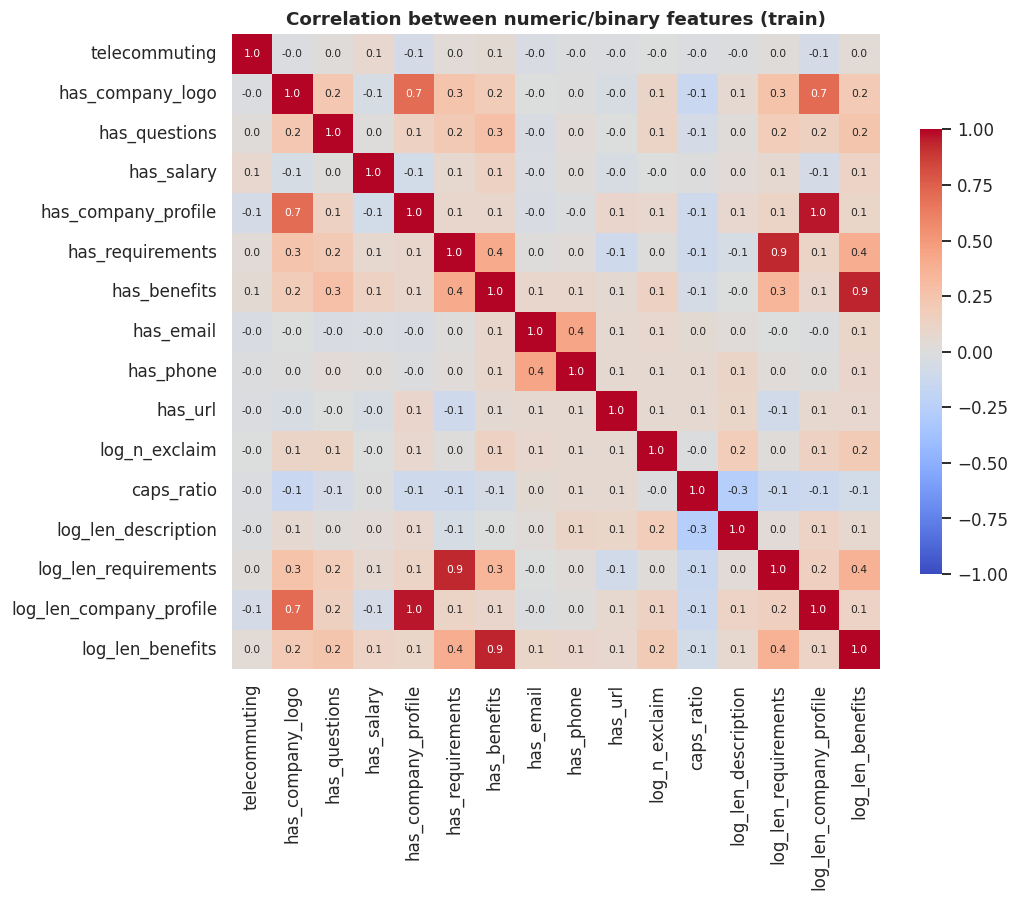

Pairs with |r| > 0.8:
   ('has_company_profile', 'log_len_company_profile', 0.96)
   ('has_requirements', 'log_len_requirements', 0.93)
   ('has_benefits', 'log_len_benefits', 0.94)


In [19]:
corr = X_train[NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation between numeric/binary features (train)")
save_fig("08_feature_correlation")
plt.show()

pairs = [(a, b, float(round(corr.loc[a, b], 2))) for i, a in enumerate(NUM_COLS) for b in NUM_COLS[i + 1:] if abs(corr.loc[a, b]) > 0.8]
print("Pairs with |r| > 0.8:")
for p in pairs: print("  ", p)

The `has_*` flags and the matching `log_len_*` features are almost the same variable, because a missing field has length 0. We test below whether dropping the three redundant length features loses anything.

**5.3 Relevance check (mutual information with the target).**

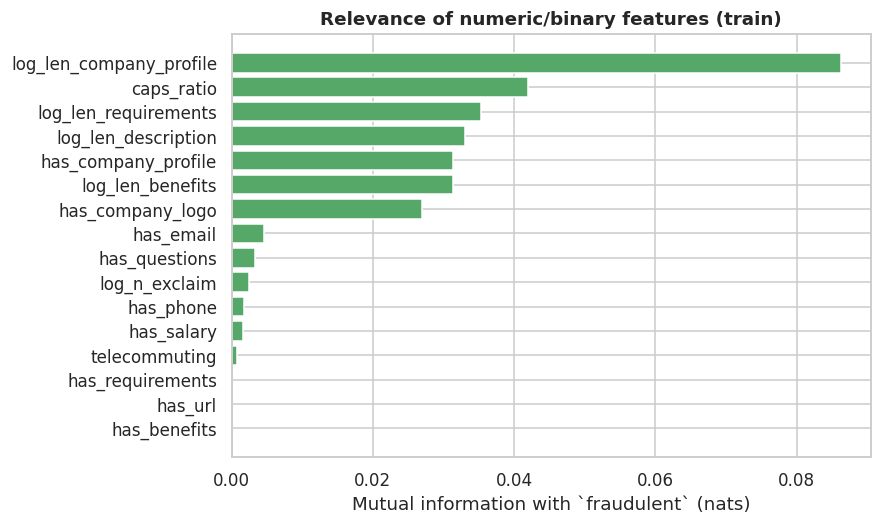

In [20]:
from sklearn.feature_selection import mutual_info_classif

is_discrete = [c not in ("log_n_exclaim", "caps_ratio") and not c.startswith("log_len_") for c in NUM_COLS]
mi = pd.Series(mutual_info_classif(X_train[NUM_COLS], y_train, discrete_features=is_discrete, random_state=SEED),
               index=NUM_COLS).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(mi.index, mi.values, color="#55A868")
ax.set_xlabel("Mutual information with `fraudulent` (nats)")
ax.set_title("Relevance of numeric/binary features (train)")
save_fig("09_mutual_information")
plt.show()

**5.4 Does each feature group help? (cross-validated ablation).** Same model each time (Logistic Regression, C = 10), only the feature set changes; score = mean PR-AUC over 5 group-aware CV folds on the training set.

*Decision rule (fixed in advance):* keep the **simplest** feature set whose mean PR-AUC is within 0.005 of the best one.

In [21]:
REDUNDANT = ["log_len_company_profile", "log_len_requirements", "log_len_benefits"]
NUM_REDUCED = [c for c in NUM_COLS if c not in REDUNDANT]

def cv_score(prep, C=10):
    pipe = Pipeline([("prep", prep), ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=3000))])
    s = cross_val_score(pipe, X_train, y_train, scoring="average_precision", cv=cv, groups=g_train)
    return s.mean(), s.std()

group_configs = {
    "A: text only":                            dict(cat_cols=[],       num_cols=[]),
    "B: text + categorical":                   dict(cat_cols=CAT_COLS, num_cols=[]),
    "C: text + numeric/binary":                dict(cat_cols=[],       num_cols=NUM_COLS),
    "D: text + categorical + numeric (all)":   dict(cat_cols=CAT_COLS, num_cols=NUM_COLS),
    "E: as D, minus 3 redundant length feats": dict(cat_cols=CAT_COLS, num_cols=NUM_REDUCED),
}
t0 = time.time()
rows = []
for name, kw in group_configs.items():
    m, s = cv_score(make_preprocessor(**kw))
    rows.append({"feature set": name, "extra columns": len(kw["cat_cols"]) + len(kw["num_cols"]), "PR-AUC mean": m, "PR-AUC std": s})
    print(f"  done: {name}")
abl = pd.DataFrame(rows).set_index("feature set")
print(f"({time.time() - t0:.0f}s)")
display(abl.round(4))

best_m = abl["PR-AUC mean"].max()
ok = abl[abl["PR-AUC mean"] >= best_m - 0.005]
chosen_name = ok["extra columns"].idxmin()
FINAL_CAT_COLS, FINAL_NUM_COLS = group_configs[chosen_name]["cat_cols"], group_configs[chosen_name]["num_cols"]
print(f"\nDecision rule picks: {chosen_name}")
print(f"  -> {len(FINAL_CAT_COLS)} categorical + {len(FINAL_NUM_COLS)} numeric/binary columns kept")

  done: A: text only


  done: B: text + categorical


  done: C: text + numeric/binary


  done: D: text + categorical + numeric (all)


  done: E: as D, minus 3 redundant length feats
(187s)


,extra columns,PR-AUC mean,PR-AUC std
feature set,,,
A: text only,0,0.7685,0.0387
B: text + categorical,6,0.7852,0.0388
C: text + numeric/binary,16,0.7985,0.0186
D: text + categorical + numeric (all),22,0.8211,0.0213
"E: as D, minus 3 redundant length feats",19,0.8138,0.0234



Decision rule picks: D: text + categorical + numeric (all)
  -> 6 categorical + 16 numeric/binary columns kept


**5.5 How many TF-IDF terms do we need?** Text is the biggest block of features (tens of thousands of columns). We test keeping only the top-*k* terms by chi-squared score (`SelectKBest`). Chi-squared is computed **inside each CV fold** from that fold's training part, so there is no leakage. Same decision rule as above.

In [22]:
t0 = time.time()
rows = []
for k in [2000, 5000, 10000, None]:
    prep = make_preprocessor(cat_cols=FINAL_CAT_COLS, num_cols=FINAL_NUM_COLS, k_best=k)
    m, s = cv_score(prep)
    rows.append({"body terms kept": k if k else "all (30,000)", "k": k if k else 30000, "PR-AUC mean": m, "PR-AUC std": s})
    print(f"  done: k={k}")
kb = pd.DataFrame(rows).set_index("body terms kept")
print(f"({time.time() - t0:.0f}s)")
display(kb.drop(columns="k").round(4))

best_m = kb["PR-AUC mean"].max()
ok = kb[kb["PR-AUC mean"] >= best_m - 0.005]
k_choice = int(ok["k"].min())
FINAL_K_BEST = None if k_choice == 30000 else k_choice
print(f"\nDecision rule picks: keep {'all 30,000' if FINAL_K_BEST is None else f'{FINAL_K_BEST:,}'} body terms (LR/SVM); k_best={FINAL_K_BEST}")

  done: k=2000


  done: k=5000


  done: k=10000


  done: k=None
(148s)


,PR-AUC mean,PR-AUC std
body terms kept,,
2000,0.7935,0.0265
5000,0.8112,0.0242
10000,0.8192,0.0258
"all (30,000)",0.8211,0.0213



Decision rule picks: keep 10,000 body terms (LR/SVM); k_best=10000


### 5.6 Decision

The two tables above drive the decisions automatically through the pre-declared rule; the resulting feature set is stored in `FINAL_CAT_COLS`, `FINAL_NUM_COLS` and `FINAL_K_BEST` and used by every model below.

## 6. Modelling

### 6.1 Metrics
* With ~5% fake ads, **accuracy** rewards a model that never flags anything (Section 2.1).
* **Model selection metric: PR-AUC** (average precision) — threshold-free, focuses on the rare fake class.
* **Reporting metrics** (fake class): precision (of the ads we flag, how many are really fake), recall (of the fake ads, how many we catch), F1, plus ROC-AUC and MCC.

### 6.2 The three models

| Model | Why it fits this problem |
|---|---|
| **Logistic Regression** | The standard strong baseline for sparse TF-IDF text; gives probabilities and interpretable word weights |
| **Linear SVM** (`LinearSVC`) | Margin-based linear model, often the best classic choice for high-dimensional text |
| **Random Forest** | Non-linear tree ensemble that can combine metadata flags and words in interaction; different bias from the two linear models. Trees do not benefit from 30,000 sparse columns, so it gets a smaller vocabulary (3,000 unigrams) |

**Imbalance handling:** `class_weight="balanced"` (errors on the rare fake class cost ~20x more) instead of oversampling. SMOTE interpolates between sparse TF-IDF vectors, which creates non-existent "documents"; class weights are simpler and safer here.

**Hyper-parameters** are tuned with `GridSearchCV` on the training set (5-fold group-aware CV, scoring = PR-AUC). The vectoriser is re-fitted inside every fold; a cache avoids repeating identical work across parameter values.

In [23]:
from joblib import Memory
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.svm import LinearSVC

memory = Memory(tempfile.mkdtemp(prefix="prep_cache_"), verbose=0)

models = {
    "Logistic Regression": dict(
        pipe=Pipeline([("prep", make_preprocessor(FINAL_CAT_COLS, FINAL_NUM_COLS, k_best=FINAL_K_BEST)),
                       ("clf", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=SEED))], memory=memory),
        grid={"clf__C": [3, 10, 30, 100]}, method="decision_function", default_thr=0.0),
    "Linear SVM": dict(
        pipe=Pipeline([("prep", make_preprocessor(FINAL_CAT_COLS, FINAL_NUM_COLS, k_best=FINAL_K_BEST)),
                       ("clf", LinearSVC(class_weight="balanced", max_iter=20000, random_state=SEED))], memory=memory),
        grid={"clf__C": [0.1, 0.3, 1, 3]}, method="decision_function", default_thr=0.0),
    "Random Forest": dict(
        pipe=Pipeline([("prep", make_preprocessor(FINAL_CAT_COLS, FINAL_NUM_COLS, body_max_features=3000, body_ngrams=(1, 1), scale_num=False)),
                       ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))], memory=memory),
        grid={"clf__min_samples_leaf": [1, 2, 4]}, method="predict_proba", default_thr=0.5),
}

def get_scores(model, X_):
    """Continuous 'fakeness' score: decision_function if available, otherwise P(fake)."""
    return model.decision_function(X_) if hasattr(model, "decision_function") else model.predict_proba(X_)[:, 1]

fitted, grid_tables = {}, {}
for name, cfg in models.items():
    t0 = time.time()
    gs = GridSearchCV(cfg["pipe"], cfg["grid"], scoring="average_precision", cv=cv, n_jobs=1, refit=True)
    gs.fit(X_train, y_train, groups=g_train)
    fitted[name] = gs
    tab = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]].rename(
        columns={"mean_test_score": "CV PR-AUC", "std_test_score": "std"})
    grid_tables[name] = tab
    print(f"\n{name}  |  best params: {gs.best_params_}  |  CV PR-AUC = {gs.best_score_:.4f}  ({time.time() - t0:.0f}s)")
    display(tab.round(4))


Logistic Regression  |  best params: {'clf__C': 30}  |  CV PR-AUC = 0.8192  (75s)


,params,CV PR-AUC,std
0,{'clf__C': 3},0.8058,0.0265
1,{'clf__C': 10},0.8192,0.0258
2,{'clf__C': 30},0.8192,0.0250
3,{'clf__C': 100},0.8150,0.0213



Linear SVM  |  best params: {'clf__C': 1}  |  CV PR-AUC = 0.8165  (88s)


,params,CV PR-AUC,std
0,{'clf__C': 0.1},0.7904,0.0278
1,{'clf__C': 0.3},0.8137,0.0235
2,{'clf__C': 1},0.8165,0.0236
3,{'clf__C': 3},0.8151,0.0264



Random Forest  |  best params: {'clf__min_samples_leaf': 1}  |  CV PR-AUC = 0.7631  (348s)


,params,CV PR-AUC,std
0,{'clf__min_samples_leaf': 1},0.7631,0.0394
1,{'clf__min_samples_leaf': 2},0.7369,0.0384
2,{'clf__min_samples_leaf': 4},0.7262,0.0347


## 7. Model comparison and decision threshold (still training data only)

A classifier outputs a score; the **threshold** turns it into "fake / real". The default (0 for the linear models, 0.5 for the forest) is not necessarily best on imbalanced data. We collect **out-of-fold (OOF) scores** — every training ad is scored by a model that never saw it — and pick the threshold that maximises F1 on those OOF scores. The test set plays no role.

The final model is chosen by **highest cross-validated PR-AUC** (decided now, before looking at the test set).

OOF predictions done (159s)


,best params,CV PR-AUC (grid),OOF PR-AUC (pooled),OOF ROC-AUC,tuned threshold,OOF precision,OOF recall,OOF F1
model,,,,,,,,
Logistic Regression,{'clf__C': 30},0.819,0.817,0.975,0.423,0.800,0.724,0.760
Linear SVM,{'clf__C': 1},0.816,0.815,0.976,0.049,0.827,0.718,0.769
Random Forest,{'clf__min_samples_leaf': 1},0.763,0.761,0.976,0.210,0.664,0.702,0.683



Selected model (highest CV PR-AUC): Logistic Regression


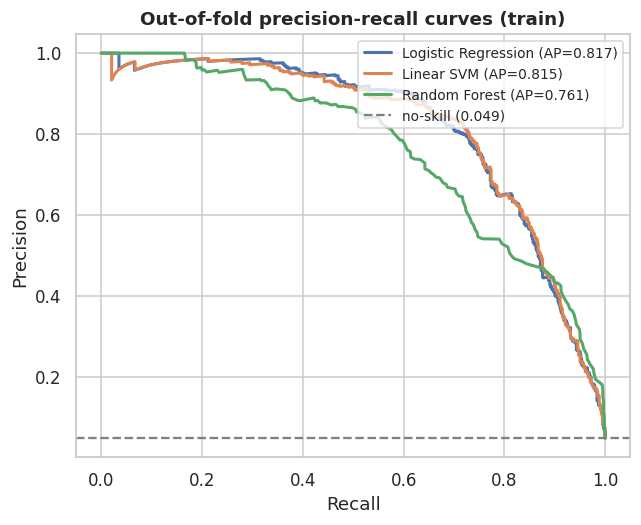

In [24]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, precision_score,
                             recall_score, f1_score, matthews_corrcoef, accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay, roc_curve)

def best_f1_threshold(y_true, scores):
    p, r, thr = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return float(thr[i]), float(f1[i])

oof, thr = {}, {}
t0 = time.time()
for name, gs in fitted.items():
    s = cross_val_predict(clone(gs.best_estimator_), X_train, y_train, cv=cv, groups=g_train, method=models[name]["method"])
    oof[name] = s[:, 1] if s.ndim == 2 else s
    thr[name], _ = best_f1_threshold(y_train, oof[name])
print(f"OOF predictions done ({time.time() - t0:.0f}s)")

rows = []
for name, gs in fitted.items():
    pred = (oof[name] >= thr[name]).astype(int)
    rows.append({"model": name,
                 "best params": str(gs.best_params_),
                 "CV PR-AUC (grid)": gs.best_score_,
                 "OOF PR-AUC (pooled)": average_precision_score(y_train, oof[name]),
                 "OOF ROC-AUC": roc_auc_score(y_train, oof[name]),
                 "tuned threshold": thr[name],
                 "OOF precision": precision_score(y_train, pred),
                 "OOF recall": recall_score(y_train, pred),
                 "OOF F1": f1_score(y_train, pred)})
cv_table = pd.DataFrame(rows).set_index("model")
display(cv_table.round(3))

best_name = cv_table["CV PR-AUC (grid)"].idxmax()
print(f"\nSelected model (highest CV PR-AUC): {best_name}")

fig, ax = plt.subplots(figsize=(6.5, 5))
for name in fitted:
    p, r, _ = precision_recall_curve(y_train, oof[name])
    ax.plot(r, p, lw=2, label=f"{name} (AP={average_precision_score(y_train, oof[name]):.3f})")
ax.axhline(y_train.mean(), ls="--", color="gray", label=f"no-skill ({y_train.mean():.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Out-of-fold precision-recall curves (train)")
ax.legend(loc="upper right", fontsize=9)
save_fig("10_oof_pr_curves")
plt.show()

## 8. Final evaluation on the test set

The test set is used **once**, with models and thresholds that were fixed before this point. Alongside the three models we report the **"always real"** baseline (`DummyClassifier`), to show what accuracy alone hides.

In [25]:
test_scores = {name: get_scores(gs.best_estimator_, X_test) for name, gs in fitted.items()}

def metrics_row(y_true, score, t):
    pred = (score >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, pred),
            "precision (fake)": precision_score(y_true, pred, zero_division=0),
            "recall (fake)": recall_score(y_true, pred),
            "F1 (fake)": f1_score(y_true, pred),
            "MCC": matthews_corrcoef(y_true, pred),
            "PR-AUC": average_precision_score(y_true, score),
            "ROC-AUC": roc_auc_score(y_true, score),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_scores = dummy.predict_proba(X_test)[:, 1]
dummy_row = metrics_row(y_test, dummy_scores, 0.5)

tuned = pd.DataFrame({n: metrics_row(y_test, test_scores[n], thr[n]) for n in fitted}).T
tuned.loc["Baseline: always 'real'"] = pd.Series(dummy_row)
default = pd.DataFrame({n: metrics_row(y_test, test_scores[n], models[n]["default_thr"]) for n in fitted}).T
for df_m in (tuned, default):
    df_m[["TP", "FP", "FN", "TN"]] = df_m[["TP", "FP", "FN", "TN"]].astype(int)

# sanity checks: everything must be internally consistent
for df_m in (tuned, default):
    assert (df_m[["TP", "FP", "FN", "TN"]].sum(axis=1) == len(y_test)).all()
    assert ((df_m["PR-AUC"] >= 0) & (df_m["PR-AUC"] <= 1)).all()
print("Test set:", len(y_test), "ads,", int(y_test.sum()), "fake")
print("\n=== Test results, CV-tuned threshold (main result) ===")
display(tuned.round(3))
print("\n=== Test results, default threshold (for comparison) ===")
display(default.round(3))

Test set: 3520 ads, 171 fake

=== Test results, CV-tuned threshold (main result) ===


,accuracy,precision (fake),recall (fake),F1 (fake),MCC,PR-AUC,ROC-AUC,TP,FP,FN,TN
Logistic Regression,0.977,0.817,0.678,0.741,0.733,0.778,0.946,116,26,55,3323
Linear SVM,0.978,0.842,0.684,0.755,0.748,0.780,0.941,117,22,54,3327
Random Forest,0.966,0.640,0.696,0.667,0.650,0.725,0.961,119,67,52,3282
Baseline: always 'real',0.951,0.000,0.000,0.000,0.000,0.049,0.500,0,0,171,3349



=== Test results, default threshold (for comparison) ===


,accuracy,precision (fake),recall (fake),F1 (fake),MCC,PR-AUC,ROC-AUC,TP,FP,FN,TN
Logistic Regression,0.977,0.805,0.702,0.750,0.740,0.778,0.946,120,29,51,3320
Linear SVM,0.978,0.832,0.696,0.758,0.750,0.780,0.941,119,24,52,3325
Random Forest,0.961,0.971,0.193,0.322,0.424,0.725,0.961,33,1,138,3348


### 8.1 How certain are these numbers? (bootstrap 95% confidence intervals)

In [26]:
rng = np.random.default_rng(SEED)
def bootstrap_ci(y_true, score, t, n_boot=1000):
    n, aps, f1s = len(y_true), [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y_true[idx].sum() == 0:
            continue
        aps.append(average_precision_score(y_true[idx], score[idx]))
        f1s.append(f1_score(y_true[idx], (score[idx] >= t).astype(int), zero_division=0))
    return np.percentile(aps, [2.5, 97.5]), np.percentile(f1s, [2.5, 97.5])

rows = []
for n in fitted:
    (ap_lo, ap_hi), (f_lo, f_hi) = bootstrap_ci(y_test, test_scores[n], thr[n])
    rows.append({"model": n,
                 "PR-AUC": f"{tuned.loc[n, 'PR-AUC']:.3f}  [{ap_lo:.3f}, {ap_hi:.3f}]",
                 "F1 (fake)": f"{tuned.loc[n, 'F1 (fake)']:.3f}  [{f_lo:.3f}, {f_hi:.3f}]"})
display(pd.DataFrame(rows).set_index("model"))
print(f"Only {int(y_test.sum())} fake ads are in the test set, so the intervals are wide: small differences between models are within noise.")

,PR-AUC,F1 (fake)
model,,
Logistic Regression,"0.778 [0.722, 0.834]","0.741 [0.688, 0.795]"
Linear SVM,"0.780 [0.714, 0.834]","0.755 [0.699, 0.806]"
Random Forest,"0.725 [0.668, 0.785]","0.667 [0.612, 0.721]"


Only 171 fake ads are in the test set, so the intervals are wide: small differences between models are within noise.


### 8.2 Confusion matrices and curves

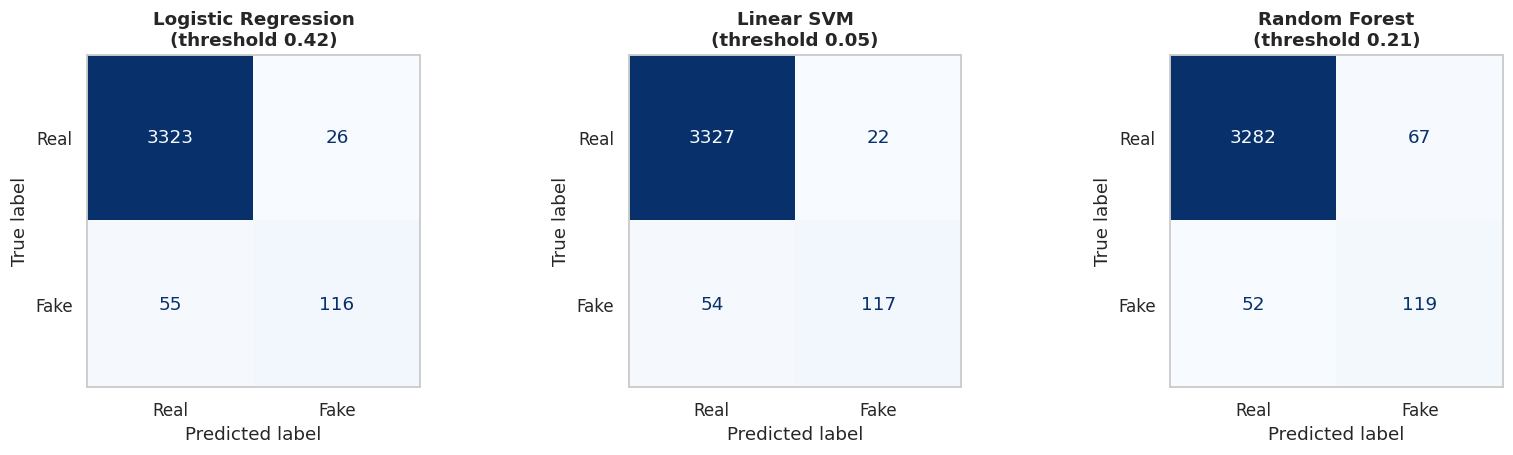

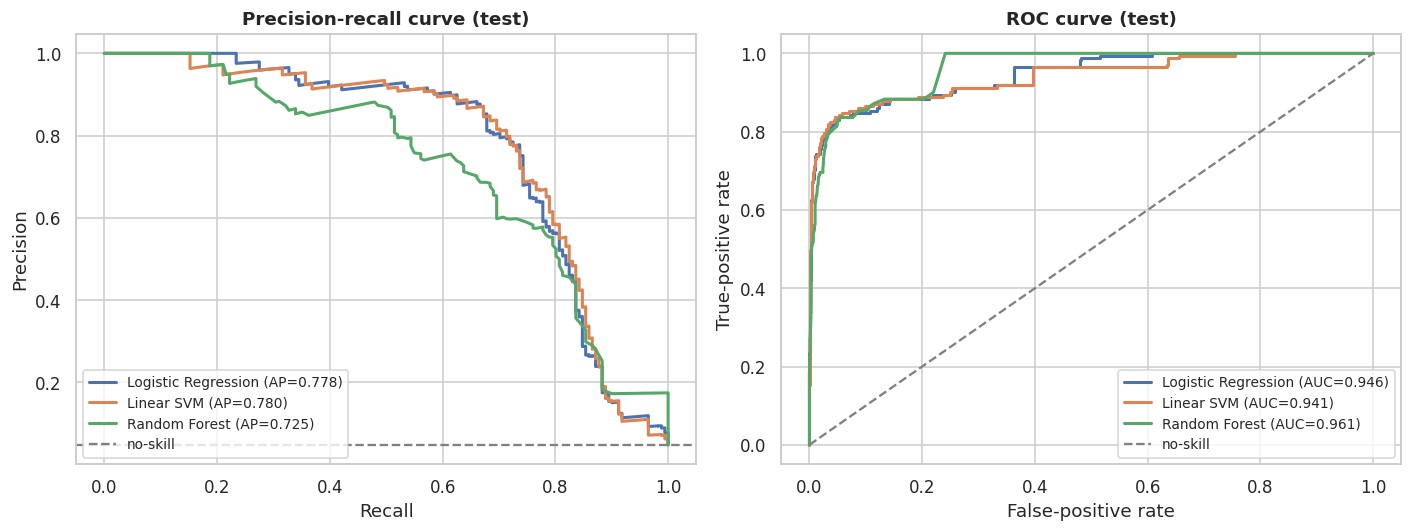

Classification report for the selected model (Logistic Regression), test set:
              precision    recall  f1-score   support

        real      0.984     0.992     0.988      3349
        fake      0.817     0.678     0.741       171

    accuracy                          0.977      3520
   macro avg      0.900     0.835     0.865      3520
weighted avg      0.976     0.977     0.976      3520



In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, n in zip(axes, fitted):
    pred = (test_scores[n] >= thr[n]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Real", "Fake"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{n}\n(threshold {thr[n]:.2f})")
    ax.grid(False)
plt.tight_layout()
save_fig("11_confusion_matrices")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n in fitted:
    p, r, _ = precision_recall_curve(y_test, test_scores[n])
    axes[0].plot(r, p, lw=2, label=f"{n} (AP={tuned.loc[n, 'PR-AUC']:.3f})")
    fpr, tpr, _ = roc_curve(y_test, test_scores[n])
    axes[1].plot(fpr, tpr, lw=2, label=f"{n} (AUC={tuned.loc[n, 'ROC-AUC']:.3f})")
axes[0].axhline(y_test.mean(), ls="--", color="gray", label="no-skill")
axes[1].plot([0, 1], [0, 1], ls="--", color="gray", label="no-skill")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test)")
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC curve (test)")
axes[0].legend(loc="lower left", fontsize=9); axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_fig("12_test_curves")
plt.show()

print(f"Classification report for the selected model ({best_name}), test set:")
print(classification_report(y_test, (test_scores[best_name] >= thr[best_name]).astype(int), target_names=["real", "fake"], digits=3))

## 9. Interpretation, error analysis and robustness

### 9.1 What drives the predictions?
For a linear model the coefficients show which features push an ad towards "fake" (positive) or "real" (negative). Numeric features are standardised, TF-IDF values are not, so compare *within* a group rather than across groups.

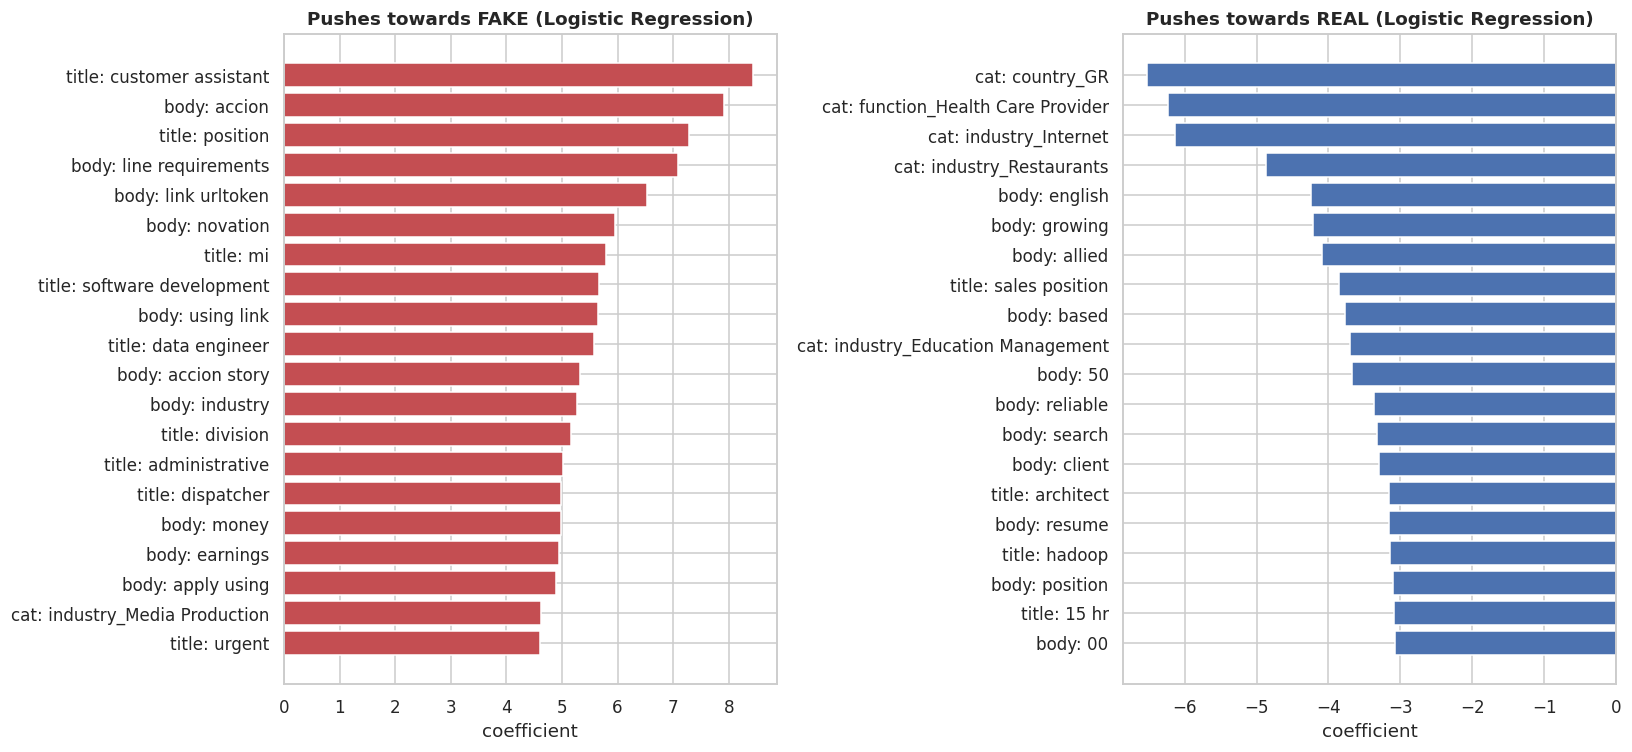

13,881 features in the Logistic Regression model.


In [28]:
lin_name = best_name if best_name in ("Logistic Regression", "Linear SVM") else "Logistic Regression"
pipe_lin = fitted[lin_name].best_estimator_
feat_names = pipe_lin.named_steps["prep"].get_feature_names_out()
coefs = pipe_lin.named_steps["clf"].coef_.ravel()
assert len(feat_names) == len(coefs)

def pretty(n):
    grp, rest = n.split("__", 1)
    return f"{grp}: {rest}"
coef_df = pd.DataFrame({"feature": [pretty(n) for n in feat_names], "coef": coefs})
top_pos = coef_df.nlargest(20, "coef").iloc[::-1]
top_neg = coef_df.nsmallest(20, "coef").iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].barh(top_pos["feature"], top_pos["coef"], color=COLORS[1]); axes[0].set_title(f"Pushes towards FAKE ({lin_name})")
axes[1].barh(top_neg["feature"], top_neg["coef"], color=COLORS[0]); axes[1].set_title(f"Pushes towards REAL ({lin_name})")
for ax in axes: ax.set_xlabel("coefficient")
plt.tight_layout()
save_fig("13_top_coefficients")
plt.show()
print(f"{len(coefs):,} features in the {lin_name} model.")

### 9.2 Error analysis (test set)

In [29]:
pred_best = (test_scores[best_name] >= thr[best_name])
err = df_test.assign(score=test_scores[best_name], y=y_test, pred=pred_best.astype(int))
err["snippet"] = err["description"].str.replace(r"\s+", " ", regex=True).str[:170]
cols = ["title", "score", "snippet"]

print(f"FALSE NEGATIVES (fake ads we missed): {int(((y_test == 1) & ~pred_best).sum())} -- the 6 with the lowest scores")
display(err[(err.y == 1) & (err.pred == 0)].nsmallest(6, "score")[cols].round(2))
print(f"\nFALSE POSITIVES (real ads flagged as fake): {int(((y_test == 0) & pred_best).sum())} -- the 6 with the highest scores")
display(err[(err.y == 0) & (err.pred == 1)].nlargest(6, "score")[cols].round(2))

FALSE NEGATIVES (fake ads we missed): 55 -- the 6 with the lowest scores


,title,score,snippet
3498,"Agency Sales Managers $150-$175,000/yr",-11.71,We provide No Credit Check Financing to customers of Small and Medium size Businesses and can help 90% of ...
3455,"Account Sales Managers $80-$130,000/yr",-10.30,We provide No Credit Check Financing to customers of Small and Medium size Businesses and can help 90% of ...
3504,"Agency Sales Managers $150-$175,000/yr",-9.89,We provide No Credit Check Financing to customers of Small and Medium size Businesses and can help 90% of ...
686,"Agency Sales Managers $150-$175,000/yr",-9.86,We provide No Credit Check Financing to customers of Small and Medium size Businesses and can help 90% of ...
1071,"Agency Sales Managers $150-$175,000/yr",-9.86,We provide No Credit Check Financing to customers of Small and Medium size Businesses and can help 90% of ...
3465,"Agency Sales Managers $150-$175,000/yr",-9.86,We provide No Credit Check Financing to customers of Small and Medium size Businesses and can help 90% of ...



FALSE POSITIVES (real ads flagged as fake): 26 -- the 6 with the highest scores


,title,score,snippet
1516,Junior Pa,5.63,Are you aged 16 to 21 and looking to get a flying start in your career? Our new Youth On-Boarding Programm...
734,Customer Service,5.29,Our client is seeking an Customer Service with 1 plus years of experience.The ideal candidate must have-1 ...
1090,Tankage,4.60,A company in oil &amp; gas that has grown into one of Malaysia’s leading integrated specialist technical s...
1789,Front-end JavaScript Developer,4.45,"Since Pilot is dynamically developing, we are constantly looking for new people to join our team. If you w..."
65,Data Entry/Customer Service Rep,4.33,As a Data Entry/Customer Service Representative you will be responsible for simultaneously managing inboun...
215,BILINGUAL JAPANESE RISK MANAGEMENT OFFICER,3.80,BILINGUAL JAPANESE RISK MANAGEMENT OFFICERLOCATION: Northern NJTYPE OF EMPLOYMENT: Full-Time PermanentRESP...


### 9.3 Robustness (stress test): unseen scam campaigns and companies
Even with near-duplicates separated, one thing can still leak: the **same company** (or the same scam campaign) posting *different* jobs, so its company profile appears on both sides. A stricter question: **does the model still work on companies and campaigns it has never seen?** We re-split so that near-duplicate groups *and* ads sharing a company profile stay together, re-fit each model with its tuned hyper-parameters, and compare with the main test results. Only threshold-free metrics are used here.

In [30]:
edges_company = same_key_edges(df["company_profile"])
grp_strict = groups_from_edges(len(df), edges_near, edges_desc, edges_company)
sz = np.bincount(grp_strict)
print(f"Strict groups: {len(sz):,} (largest = {sz.max()} ads, {sz.max() / len(df) * 100:.1f}% of the data)")

tr2, te2 = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, groups=grp_strict))
assert len(set(grp_strict[tr2]) & set(grp_strict[te2])) == 0
print(f"Strict split: train {len(tr2):,} ads ({int(y[tr2].sum())} fake) | test {len(te2):,} ads ({int(y[te2].sum())} fake)")

rows = []
t0 = time.time()
for n, gs in fitted.items():
    m2 = clone(gs.best_estimator_).fit(X.iloc[tr2], y[tr2])
    s2 = get_scores(m2, X.iloc[te2])
    rows.append({"model": n,
                 "PR-AUC (main test)": tuned.loc[n, "PR-AUC"], "PR-AUC (unseen companies)": average_precision_score(y[te2], s2),
                 "ROC-AUC (main test)": tuned.loc[n, "ROC-AUC"], "ROC-AUC (unseen companies)": roc_auc_score(y[te2], s2)})
print(f"({time.time() - t0:.0f}s)")
stress = pd.DataFrame(rows).set_index("model")
display(stress.round(3))

Strict groups: 4,359 (largest = 723 ads, 4.1% of the data)


Strict split: train 14,079 ads (685 fake) | test 3,520 ads (171 fake)


(44s)


,PR-AUC (main test),PR-AUC (unseen companies),ROC-AUC (main test),ROC-AUC (unseen companies)
model,,,,
Logistic Regression,0.778,0.534,0.946,0.896
Linear SVM,0.780,0.542,0.941,0.903
Random Forest,0.725,0.366,0.961,0.795


## 10. Save the model and try it on new ads

The saved file contains the whole pipeline (TF-IDF, encoders, scaler, classifier) plus the tuned threshold. Together with `job_features.py` it is everything the Streamlit app needs.

In [31]:
import joblib

final_model = fitted[best_name].best_estimator_
final_model.set_params(memory=None)          # drop the temporary cache reference before saving
bundle = {"model": final_model, "threshold": float(thr[best_name]), "name": best_name,
          "score_type": models[best_name]["method"], "sklearn_version": sklearn.__version__}
joblib.dump(bundle, "fake_job_model.joblib")

# Reload and verify that the saved model reproduces the test scores exactly
reloaded = joblib.load("fake_job_model.joblib")
assert np.allclose(get_scores(reloaded["model"], X_test), test_scores[best_name])
print(f"Saved fake_job_model.joblib ({os.path.getsize('fake_job_model.joblib') / 1e6:.1f} MB) and verified that reloading reproduces the test scores.")

def predict_postings(raw_df, bundle=reloaded):
    """Score raw job postings (same columns as the original CSV, without the target)."""
    feats = build_features(raw_df)
    s = get_scores(bundle["model"], feats)
    return pd.DataFrame({"score": s.round(3), "verdict": np.where(s >= bundle["threshold"], "FAKE", "REAL")}, index=raw_df.index)

# (a) four real ads from the test set: 2 fake + 2 real, with the true label for comparison
sample = pd.concat([df_test[y_test == 1].sample(2, random_state=SEED), df_test[y_test == 0].sample(2, random_state=SEED)])
demo = predict_postings(sample.drop(columns="fraudulent")).assign(true_label=np.where(sample["fraudulent"] == 1, "FAKE", "REAL"),
                                                                  title=sample["title"].str[:45])
display(demo[["title", "score", "verdict", "true_label"]])

# (b) a hand-written example, to show how the function is called on a brand-new ad
new_ad = pd.DataFrame([{
    "title": "Data Entry Clerk - Work From Home", "location": "US, TX, Houston", "department": None, "salary_range": None,
    "company_profile": None,
    "description": "Earn $5000 weekly working from home! No experience needed. Send your bank details and a small registration fee "
                   "by email to start today!!! Limited positions available.",
    "requirements": None, "benefits": None, "telecommuting": 1, "has_company_logo": 0, "has_questions": 0,
    "employment_type": "Part-time", "required_experience": None, "required_education": None, "industry": None, "function": None}])
display(predict_postings(new_ad))

Saved fake_job_model.joblib (2.2 MB) and verified that reloading reproduces the test scores.


,title,score,verdict,true_label
3437,Data Entry/Administrative Assistant,1.729,FAKE,FAKE
1210,SECURITY OFFICER,-0.555,REAL,FAKE
1909,Functional Business Analyst,-14.271,REAL,REAL
2720,Customer Service Associate - Part Time,-8.842,REAL,REAL


,score,verdict
0,3.004,FAKE


## 11. Summary

In [32]:
b = tuned.loc[best_name]
print("=" * 78)
print("FINAL SUMMARY")
print("=" * 78)
print(f"Data            : {len(df):,} unique postings, {int(y.sum())} fake ({y.mean()*100:.2f}%)")
print(f"Split           : {len(y_train):,} train / {len(y_test):,} test (stratified, near-duplicate ads kept together)")
print(f"Feature set     : {len(FINAL_CAT_COLS)} categorical + {len(FINAL_NUM_COLS)} numeric columns, body-term limit: {FINAL_K_BEST or 'none'}")
print(f"Selected model  : {best_name}  {fitted[best_name].best_params_}")
print(f"Threshold       : {thr[best_name]:.3f} (tuned on out-of-fold train predictions)")
print("-" * 78)
print(f"Test precision  : {b['precision (fake)']:.3f}   (of the ads flagged as fake, this share really is fake)")
print(f"Test recall     : {b['recall (fake)']:.3f}   (of all fake ads, this share is caught)")
print(f"Test F1         : {b['F1 (fake)']:.3f}")
print(f"Test PR-AUC     : {b['PR-AUC']:.3f}   (no-skill level = {y_test.mean():.3f})")
print(f"Test ROC-AUC    : {b['ROC-AUC']:.3f}")
base = tuned.loc["Baseline: always 'real'"]
print(f"Baseline 'always real': accuracy {base['accuracy']:.3f} but recall {base['recall (fake)']:.3f}")
print("=" * 78)

FINAL SUMMARY
Data            : 17,599 unique postings, 856 fake (4.86%)
Split           : 14,079 train / 3,520 test (stratified, near-duplicate ads kept together)
Feature set     : 6 categorical + 16 numeric columns, body-term limit: 10000
Selected model  : Logistic Regression  {'clf__C': 30}
Threshold       : 0.423 (tuned on out-of-fold train predictions)
------------------------------------------------------------------------------
Test precision  : 0.817   (of the ads flagged as fake, this share really is fake)
Test recall     : 0.678   (of all fake ads, this share is caught)
Test F1         : 0.741
Test PR-AUC     : 0.778   (no-skill level = 0.049)
Test ROC-AUC    : 0.946
Baseline 'always real': accuracy 0.951 but recall 0.000


### Conclusions

**What we built.** A traditional-ML pipeline (TF-IDF + metadata, no deep learning) that flags likely-fake job postings, evaluated with an imbalance-aware protocol on the EMSCAD job-postings dataset (17,599 unique postings after de-duplication, 856 fake, 4.86%).

**Main result (held-out test set, 3,520 ads, 171 fake).** Logistic Regression (C=30, chosen by cross-validated PR-AUC before the test set was touched):

| metric | value |
|---|---|
| Precision (fake) | 0.817 |
| Recall (fake) | 0.678 |
| F1 (fake) | 0.741 |
| PR-AUC | 0.778 (no-skill = 0.049) |
| ROC-AUC | 0.946 |

Linear SVM performed essentially the same (F1 = 0.755, PR-AUC = 0.780); the bootstrap confidence intervals of the two overlap, so the difference is not meaningful. Random Forest was clearly weaker (F1 = 0.667, PR-AUC = 0.725) and needed threshold tuning just to reach a usable recall. The "always real" baseline reaches 95.1% accuracy while catching zero fake ads — the reason every comparison in this notebook uses precision/recall/F1/PR-AUC instead of accuracy.

**What drives the predictions.** Missing `company_profile`, missing company logo, and masked e-mail/phone contacts in the text are the strongest metadata signals (Section 2.4); on the text side, the model's top positive coefficients concentrate on words from a handful of recurring scam templates rather than generic "scam vocabulary" (Sections 3.4 and 9.1).

**A limitation we found and quantified, not just disclosed.** 52% of the fake ads in this dataset are near-duplicates of another fake ad (Section 4). Our split keeps near-duplicates together, so the 0.778 PR-AUC reflects genuine generalisation to a *different wording* of a known scam — not memorisation. But the stress test in Section 9.3, which holds out entire companies/campaigns, shows PR-AUC dropping to 0.534 (Linear SVM: 0.542). In plain terms: **this model is good at catching new instances of scam patterns it has seen before, and considerably weaker at catching a brand-new kind of scam it has never seen.** Any real deployment would need continuous re-training as new campaigns appear, and should be framed as a triage/priority tool for human review rather than an automatic filter.

**Limitations of the data itself.** The dataset is several years old and mostly English-language, international postings; a system for a different market (e.g. mainly Arabic-language, mainly local postings) would need re-training on locally representative data before these numbers would transfer.
